# Chapter 5: Where to draw the line: which threshold does the business choose?

*Threshold selection as a business decision · also searched as: classification threshold tuning, decision threshold, predict_proba threshold*

**Who needs the answer.** Kalpa Retail's Marketing team, who must hand the call centre a list, and Anand, whose prices decide where the list stops. The model gives a probability; the business draws the line.

**The questions on the way.** What does each possible line cost on twenty scored customers? Which line would accuracy pick, and which would the bill pick? How does the line move when the prices move?

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

import numpy as np, pandas as pd
# Invented: twenty Kalpa customers with the model's P(come back) and what happened.
scored = pd.DataFrame({
    "customer": [f"K{i:02d}" for i in range(1, 21)],
    "p_come_back": [0.92, 0.81, 0.66, 0.55, 0.43, 0.38, 0.30, 0.22, 0.18, 0.14,
                    0.11, 0.09, 0.07, 0.05, 0.035, 0.025, 0.02, 0.015, 0.01, 0.005],
    "came_back":   [1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
})
print(scored.to_string(index=False))

customer  p_come_back  came_back
     K01        0.920          1
     K02        0.810          1
     K03        0.660          0
     K04        0.550          1
     K05        0.430          0
     K06        0.380          1
     K07        0.300          0
     K08        0.220          0
     K09        0.180          1
     K10        0.140          0
     K11        0.110          0
     K12        0.090          0
     K13        0.070          0
     K14        0.050          0
     K15        0.035          1
     K16        0.025          0
     K17        0.020          0
     K18        0.015          0
     K19        0.010          0
     K20        0.005          0


## What does each line cost?

A line at threshold t nudges everyone scoring t or more. With twenty customers there are only twenty-one different lists, one per gap between scores.

**Predict before you run.** Which line has the smallest bill at Rs 40 and Rs 1,200? (a) 0.5, (b) 0.2, (c) 0.032, (d) nudge everyone.

In [2]:
COST_FP, COST_FN = 40, 1200
def at(t, cost_fp=COST_FP, cost_fn=COST_FN):
    act = scored.p_come_back >= t; y = scored.came_back == 1
    tp, fp, fn, tn = int((act & y).sum()), int((act & ~y).sum()), int((~act & y).sum()), int((~act & ~y).sum())
    return tp, fp, fn, tn, fp * cost_fp + fn * cost_fn, (tp + tn) / 20
rows = [[t, *at(t)] for t in (0.9, 0.5, 0.3, 0.2, 0.1, 0.032, 0.0)]
table = pd.DataFrame(rows, columns=["line", "TP", "FP", "FN", "TN", "bill Rs", "accuracy"])
print(table.to_string(index=False, formatters={"bill Rs": "{:,}".format, "accuracy": "{:.0%}".format}))

 line  TP  FP  FN  TN bill Rs accuracy
0.900   1   0   5  14   6,000      75%
0.500   3   1   3  13   3,640      80%
0.300   4   3   2  11   2,520      75%
0.200   4   4   2  10   2,560      70%
0.100   5   6   1   8   1,440      65%
0.032   6   9   0   5     360      55%
0.000   6  14   0   0     560      30%


**What happened.** The answer is (c). At 0.032 the list holds 15 customers, catches all 6 repeaters and wastes 9 nudges: Rs 360. Nudging everyone wastes 14: Rs 560. The default 0.5 leaves three repeaters alone: Rs 3,640.

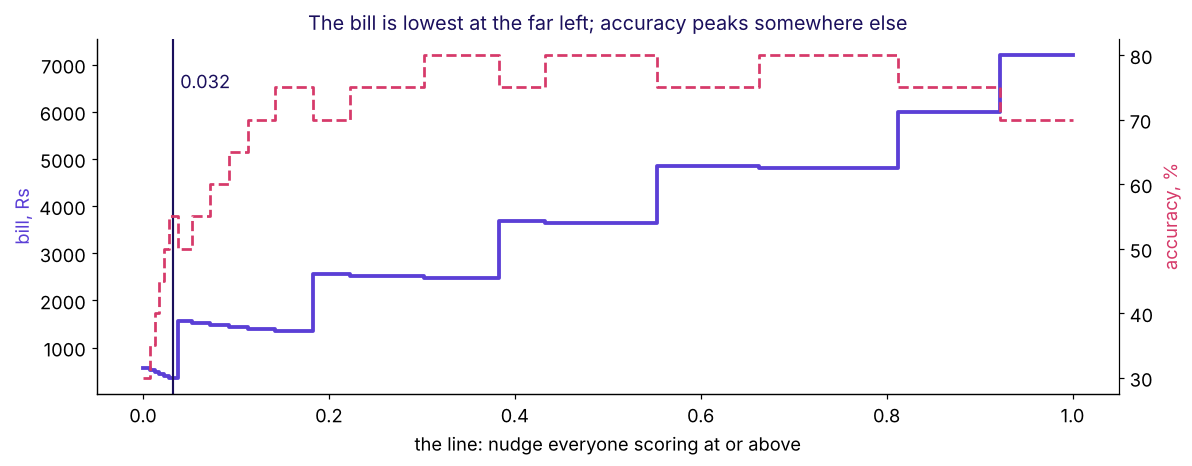

accuracy is highest (80%) at a line of 0.302, where the bill is Rs 2,480


In [3]:
grid = np.linspace(0, 1, 401)
bills = [at(t)[4] for t in grid]
accs = [at(t)[5] for t in grid]
fig, ax1 = plt.subplots(figsize=(11, 4.4))
ax1.step(grid, bills, where="post", color=VIOLET, lw=2.5, label="bill of mistakes, Rs")
ax1.axvline(1 / 31, color=INK, lw=1.4); ax1.text(0.04, 6500, "0.032", color=INK)
ax1.set_xlabel("the line: nudge everyone scoring at or above"); ax1.set_ylabel("bill, Rs", color=VIOLET)
ax2 = ax1.twinx(); ax2.step(grid, np.array(accs) * 100, where="post", color=ROSE, lw=1.8, ls="--", label="accuracy, %")
ax2.set_ylabel("accuracy, %", color=ROSE); ax2.spines["right"].set_visible(True)
ax1.set_title("The bill is lowest at the far left; accuracy peaks somewhere else", color=INK)
plt.tight_layout(); plt.show()
best_acc_t = grid[int(np.argmax(accs))]
print(f"accuracy is highest ({max(accs):.0%}) at a line of {best_acc_t:.3f}, where the bill is Rs {at(best_acc_t)[4]:,}")

## The trap: drawing the line where accuracy peaks

A hurried analyst sweeps the threshold, keeps a line where accuracy peaks and reports **"0.5 is the best threshold, 80 percent accurate"**. Accuracy is 80 percent anywhere from about 0.31 to 0.55, and at 0.5 the line leaves half the repeaters alone and costs ten times the bill at 0.032. The check is the bill at the chosen line; the fix is to choose the line from the prices, then report accuracy only as a by-product.

In [4]:
print("PASS  the cheapest line on the table is the 1-in-31 line" if min(bills) == at(1 / 31)[4] == 360 else "CHECK bill")
print("PASS  the accuracy-best line costs more than the cost line" if at(best_acc_t)[4] > at(1 / 31)[4] else "CHECK trap")

PASS  the cheapest line on the table is the 1-in-31 line
PASS  the accuracy-best line costs more than the cost line


## How does the line move when the prices move?

Keep the repeater's Rs 1,200 and change the price of acting: a Rs 40 SMS, a Rs 400 gift hamper, a Rs 1,200 store visit. The line is `cost of acting wrongly / (cost of acting wrongly + cost of failing to act)`, so it climbs as acting gets dearer.

acting costs Rs    40: line 0.032, list of 15, bill Rs 360
acting costs Rs   400: line 0.250, list of  7, bill Rs 3,600
acting costs Rs 1,200: line 0.500, list of  4, bill Rs 4,800


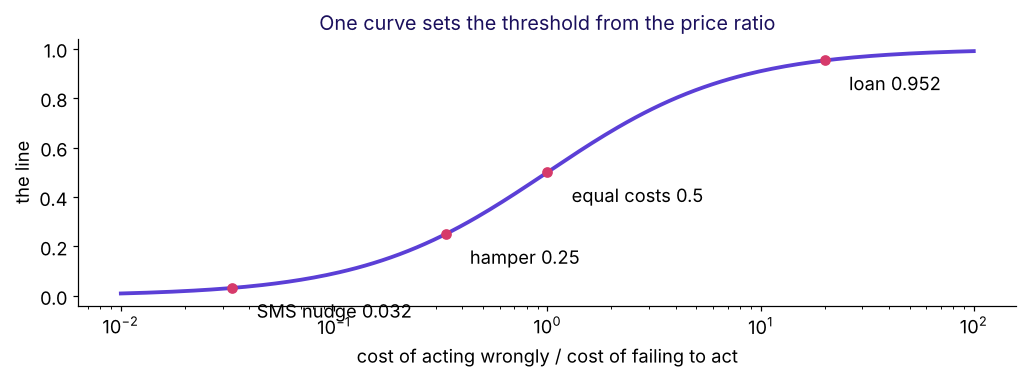

In [5]:
for cost_act in (40, 400, 1200):
    t = cost_act / (cost_act + 1200)
    tp, fp, fn, tn, b, a = at(t, cost_act, 1200)
    print(f"acting costs Rs {cost_act:>5,}: line {t:.3f}, list of {tp + fp:>2}, bill Rs {b:,}")
ratio = np.logspace(-2, 2, 200)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(ratio, ratio / (1 + ratio), color=VIOLET, lw=2.5); ax.set_xscale("log")
for r, name in ((40 / 1200, "SMS nudge 0.032"), (400 / 1200, "hamper 0.25"), (1.0, "equal costs 0.5"), (20, "loan 0.952")):
    ax.scatter(r, r / (1 + r), color=ROSE, zorder=5); ax.annotate(name, (r, r / (1 + r)), (r * 1.3, r / (1 + r) - 0.12))
ax.set_xlabel("cost of acting wrongly / cost of failing to act"); ax.set_ylabel("the line")
ax.set_title("One curve sets the threshold from the price ratio", color=INK); plt.tight_layout(); plt.show()

## A second route: nudge one customer at a time

Decide customer by customer: nudge when the expected margin beats the price, `p x 1,200 > (1 - p) x 40`. The cell checks it builds the same list as the 0.032 line.

In [6]:
ev_list = scored[scored.p_come_back * 1200 > (1 - scored.p_come_back) * 40].customer.tolist()
line_list = scored[scored.p_come_back >= 1 / 31].customer.tolist()
print(f"expected-value list: {len(ev_list)} customers; threshold list: {len(line_list)}")
print("PASS  both routes build the same list" if ev_list == line_list else "CHECK lists")

expected-value list: 15 customers; threshold list: 15
PASS  both routes build the same list


## What did this chapter establish?

| Line | List | Repeaters caught | Bill |
|---|---|---|---|
| 0.5, the default | 4 | 3 of 6 | Rs 3,640 |
| 0.032, from the prices | 15 | 6 of 6 | Rs 360 |
| nudge everyone | 20 | 6 of 6 | Rs 560 |

**The rule.** The model ranks; the business draws the line from the prices of its two mistakes. The line moves up when acting gets dearer and down when missing gets dearer, and it needs honest probabilities, which is why case 2 checks it on real scores.

**In the interview.** "Why not just use 0.5?" Because 0.5 is the line for equal costs, and Kalpa's costs are thirty to one.

Chapter 6 takes the same machinery to Rohan Desai's loans.